# 10. The Quantum Fourier Transform

The quantum Fourier transform (QFT) is the quantum version of the discrete Fourier transform and the engine behind
phase estimation and Shor's algorithm. This notebook builds it from Hadamard and controlled-phase gates, proves it
equals the discrete Fourier transform, shows why it finds periods, and uses it for phase estimation.

*Added after the course as an extension of notebooks 01–09. The circuits live in `algorithms.py` and are tested in
`tests/test_algorithms.py`.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit_aer import AerSimulator

import algorithms as alg   # circuits shared with the test suite (tests/test_algorithms.py)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## The circuit

On $n$ qubits ($N = 2^n$ basis states) the QFT maps

$$|x\rangle \;\mapsto\; \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} e^{2\pi i\, x k / N}\, |k\rangle .$$

Each qubit gets a Hadamard followed by controlled phase rotations $P(\pi/2^m)$ from the less significant qubits, and
final swaps reverse the qubit order. That is $n(n+1)/2$ rotations and Hadamards: $O(n^2)$ gates.

In [2]:
print(alg.qft(4).draw(fold=-1))

                                                                          ┌───┐   
q_0: ─────────────────────────────■─────────────────■─────────────■───────┤ H ├─X─
                                  │                 │       ┌───┐ │P(π/2) └───┘ │ 
q_1: ───────────────■─────────────┼────────■────────┼───────┤ H ├─■─────────X───┼─
                    │       ┌───┐ │        │P(π/2)  │P(π/4) └───┘           │   │ 
q_2: ──────■────────┼───────┤ H ├─┼────────■────────■───────────────────────X───┼─
     ┌───┐ │P(π/2)  │P(π/4) └───┘ │P(π/8)                                       │ 
q_3: ┤ H ├─■────────■─────────────■─────────────────────────────────────────────X─
     └───┘                                                                        


## Check 1: the circuit is exactly the discrete Fourier transform

Build the $N \times N$ DFT matrix $F_{kx} = e^{2\pi i x k/N}/\sqrt{N}$ and compare it with the unitary of the circuit,
and with Qiskit's built-in `QFTGate`.

In [3]:
from qiskit.circuit.library import QFTGate

for n in range(1, 7):
    N = 2 ** n
    dft = np.array([[np.exp(2j * np.pi * x * k / N) for x in range(N)] for k in range(N)]) / np.sqrt(N)
    ours = Operator(alg.qft(n)).data
    builtin = Operator(QFTGate(n)).data
    print(f"n = {n}  ({N:2d} states):  max |circuit - DFT| = {np.abs(ours - dft).max():.1e}   "
          f"max |circuit - QFTGate| = {np.abs(ours - builtin).max():.1e}")

n = 1  ( 2 states):  max |circuit - DFT| = 8.7e-17   max |circuit - QFTGate| = 1.4e-16
n = 2  ( 4 states):  max |circuit - DFT| = 2.7e-16   max |circuit - QFTGate| = 2.7e-16
n = 3  ( 8 states):  max |circuit - DFT| = 1.4e-15   max |circuit - QFTGate| = 1.5e-15
n = 4  (16 states):  max |circuit - DFT| = 3.8e-15   max |circuit - QFTGate| = 2.3e-15
n = 5  (32 states):  max |circuit - DFT| = 5.6e-15   max |circuit - QFTGate| = 3.5e-15
n = 6  (64 states):  max |circuit - DFT| = 8.0e-15   max |circuit - QFTGate| = 5.1e-15


## Check 2: agreement with NumPy's FFT on a random state

Applying the QFT to a state with amplitudes $a_x$ gives amplitudes $\sum_x a_x e^{2\pi i xk/N}/\sqrt N$, which is
NumPy's *inverse* FFT with orthonormal scaling (the sign convention differs between physics and signal processing).

In [4]:
rng = np.random.default_rng(42)
n = 5
amplitudes = rng.normal(size=2 ** n) + 1j * rng.normal(size=2 ** n)
amplitudes /= np.linalg.norm(amplitudes)

quantum = Statevector(amplitudes).evolve(alg.qft(n)).data
classical = np.fft.ifft(amplitudes, norm="ortho")
print(f"max difference between QFT and NumPy FFT on a random {2 ** n}-dimensional state: {np.abs(quantum - classical).max():.1e}")

max difference between QFT and NumPy FFT on a random 32-dimensional state: 1.4e-16


## Why the QFT finds periods

Take a uniform superposition over every $x$ with $x \equiv 3 \pmod{8}$ on 6 qubits ($N = 64$): the state has
**period 8**. After the QFT, all the probability sits on multiples of $N / r = 64 / 8 = 8$. Reading off where the
peaks are reveals the period, which is exactly what Shor's algorithm (notebook 11) needs.

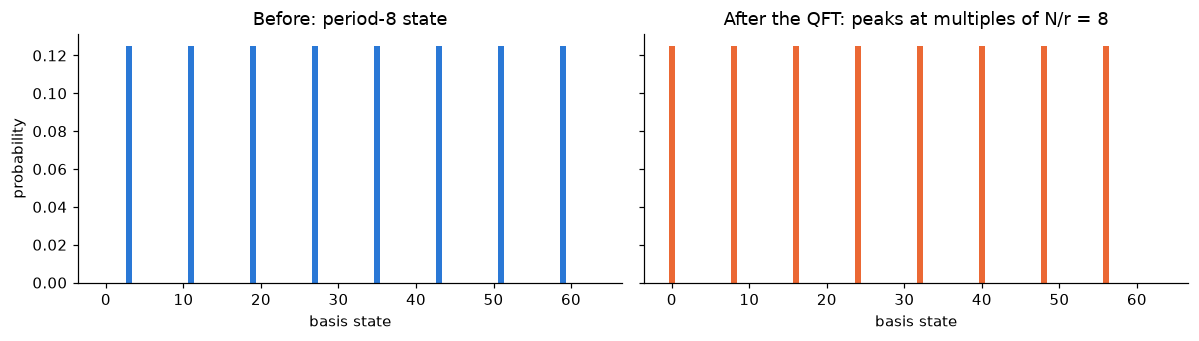

non-zero outcomes after the QFT: [0, 8, 16, 24, 32, 40, 48, 56]


In [5]:
n, period, offset = 6, 8, 3
N = 2 ** n
amplitudes = np.zeros(N)
amplitudes[offset::period] = 1
amplitudes /= np.linalg.norm(amplitudes)

after = Statevector(amplitudes).evolve(alg.qft(n)).probabilities()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
axes[0].bar(range(N), np.abs(amplitudes) ** 2, color="#2a78d6")
axes[0].set_title(f"Before: period-{period} state")
axes[1].bar(range(N), after, color="#eb6834")
axes[1].set_title("After the QFT: peaks at multiples of N/r = 8")
for ax in axes:
    ax.set_xlabel("basis state")
axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()
print("non-zero outcomes after the QFT:", [k for k in range(N) if after[k] > 1e-9])

## Cost: $O(n^2)$ gates versus $O(N \log N)$ operations

The classical FFT on $N = 2^n$ numbers takes about $N \log_2 N = n\,2^n$ operations. The QFT circuit acts on all
$2^n$ amplitudes at once with $O(n^2)$ gates. (The catch: the amplitudes cannot be read out directly, so the speed-up
only helps inside algorithms like phase estimation that end with a measurement.)

n =  2:  QFT gates =   4   classical FFT ≈ n·2^n =      8
n =  3:  QFT gates =   7   classical FFT ≈ n·2^n =     24
n =  4:  QFT gates =  12   classical FFT ≈ n·2^n =     64
n =  5:  QFT gates =  17   classical FFT ≈ n·2^n =    160
n =  6:  QFT gates =  24   classical FFT ≈ n·2^n =    384
n =  7:  QFT gates =  31   classical FFT ≈ n·2^n =    896
n =  8:  QFT gates =  40   classical FFT ≈ n·2^n =   2048
n =  9:  QFT gates =  49   classical FFT ≈ n·2^n =   4608
n = 10:  QFT gates =  60   classical FFT ≈ n·2^n =  10240
n = 11:  QFT gates =  71   classical FFT ≈ n·2^n =  22528
n = 12:  QFT gates =  84   classical FFT ≈ n·2^n =  49152


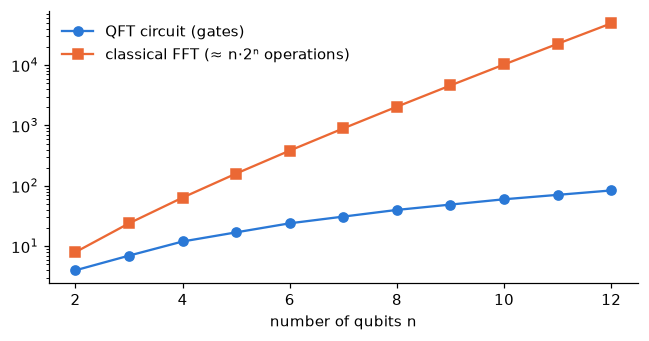

In [6]:
rows = []
for n in range(2, 13):
    ops = alg.qft(n).count_ops()
    gates = sum(ops.values())
    rows.append((n, gates, n * 2 ** n))
    print(f"n = {n:2d}:  QFT gates = {gates:3d}   classical FFT ≈ n·2^n = {n * 2 ** n:6d}")

ns, gates, fft = zip(*rows)
plt.figure(figsize=(6, 3.2))
plt.semilogy(ns, gates, "o-", color="#2a78d6", label="QFT circuit (gates)")
plt.semilogy(ns, fft, "s-", color="#eb6834", label="classical FFT (≈ n·2ⁿ operations)")
plt.xlabel("number of qubits n")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## Application: quantum phase estimation

Given a unitary $U$ and an eigenvector with $U|\psi\rangle = e^{2\pi i\varphi}|\psi\rangle$, phase estimation writes
$\varphi$ into a register of $t$ counting qubits: controlled powers $U^{2^j}$ kick the phase back onto the counting
qubits, and the **inverse** QFT turns those phases into a binary number. Here $U$ is the phase gate $P(2\pi\varphi)$
and $|\psi\rangle = |1\rangle$.

- $\varphi = 5/16$ has an exact 4-bit binary expansion, so the result is exactly $5/16$ every time.
- $\varphi = 1/3$ does not, so the outcomes concentrate on the closest 4-bit values $5/16$ and $6/16$.

φ = 5/16 (exact in 4 bits): most likely estimate 0.3125, P = 1.000


φ = 1/3 (not exact): most likely estimate 0.3125, P = 0.700


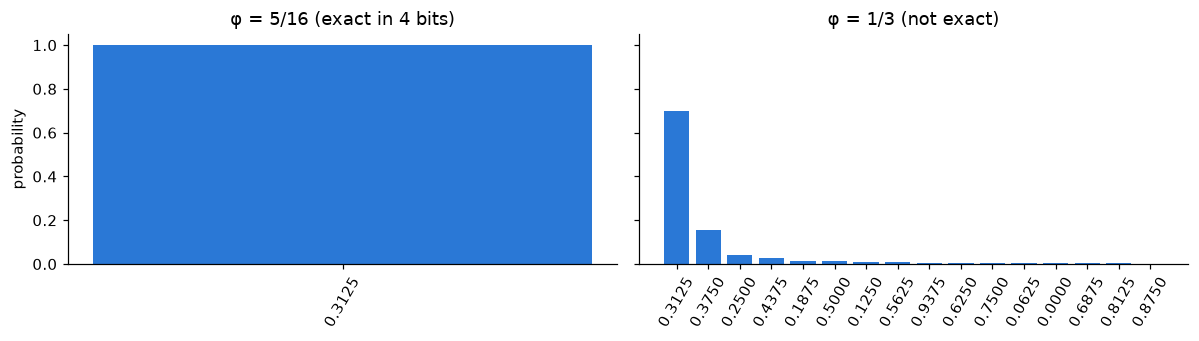

In [7]:
def phase_estimation(phi, t=4, shots=4000, seed=1):
    qc = QuantumCircuit(t + 1, t)
    qc.x(t)                                   # eigenvector |1> of the phase gate
    qc.h(range(t))
    for j in range(t):
        qc.cp(2 * np.pi * phi * 2 ** j, j, t) # controlled-U^(2^j)
    qc.compose(alg.inverse_qft(t), range(t), inplace=True)
    qc.measure(range(t), range(t))
    sim = AerSimulator(seed_simulator=seed)
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    return {int(k, 2) / 2 ** t: v / shots for k, v in sorted(counts.items(), key=lambda kv: -kv[1])}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, phi, label in zip(axes, [5 / 16, 1 / 3], ["φ = 5/16 (exact in 4 bits)", "φ = 1/3 (not exact)"]):
    estimates = phase_estimation(phi)
    ax.bar([f"{e:.4f}" for e in estimates], estimates.values(), color="#2a78d6")
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=60)
    print(f"{label}: most likely estimate {max(estimates, key=estimates.get):.4f}, "
          f"P = {max(estimates.values()):.3f}")
axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()

## Summary

- The QFT circuit equals the discrete Fourier transform exactly (Check 1) and agrees with NumPy's FFT (Check 2).
- It turns a periodic state into peaks at multiples of $N/r$, which reveals the period.
- It uses $O(n^2)$ gates, and its inverse is the last step of phase estimation.

Notebook 11 combines these pieces into Shor's algorithm.